# Weekly rhythm by facility
Yogyakarta · JogjaPulse · Role 4

Open this notebook in Google Colab and choose **Runtime → Run all**. The notebook includes the upstream summary tables needed for this figure. The final cell displays the result and writes a PNG to the current directory.

In [1]:
from pathlib import Path
from io import BytesIO
import base64, zlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

PRIMARY_PERIODS = ['2021_Dec','2022_Jan','2022_Feb_P1','2022_Feb_P2']
COLORS = {
    "education_campus": "#0072B2",
    "healthcare_hospital": "#CC6677",
    "commercial_mall": "#AA4499",
    "traditional_market": "#B57700",
    "tourism_site": "#00896B",
    "transit_hub": "#674EA7",
    "baseline_candidate": "#647482",
    "mixed_use": "#503E35",
    "no_selected_facility": "#CBD2D4",
}
LABELS = {
    "education_campus": "Campuses",
    "healthcare_hospital": "Hospitals",
    "commercial_mall": "Malls",
    "traditional_market": "Markets",
    "tourism_site": "Tourism",
    "transit_hub": "Transit",
    "baseline_candidate": "Baseline candidates",
    "mixed_use": "Mixed use",
    "no_selected_facility": "No selected facility mapped",
}
MISSING = "#d9dfe2"
BREAK = pd.Timestamp("2022-01-01")


PERIOD_NAMES = {
    "2021_Dec": "December 2021",
    "2022_Jan": "January 2022",
    "2022_Feb_P1": "February 1–15",
    "2022_Feb_P2": "February 16–28",
    "2022_Mar_Apr_Exploratory": "March–April (exploratory)",
}




## Source data
Snapshot of `data/gold/category_summary.parquet`, `data/gold/mixed_use_sensitivity.parquet` generated by the merged project pipeline. Expand the folded cell to inspect the embedded data.

In [2]:
# @title Load the embedded summary tables
encoded = {'gold/category_summary': 'eNqNmN1uI7sRhO8D5B3yAIMFm39N3h/kIld5A0ErTdaDtSVDks/ivH2+4shrb+K1ZM/IAqWZKRarq4s+b5+eH5fDt83zfFqO+2n9s/m+HPbTbnuZvx1Pf03nl6/n+TLt5sfH87R7fDlf5tPbm82P5fKwOW0vy3H9yvuB8bp5Oezn/yyHeX/9wvlhe5r36/eOl4f5tLk+a5nP09O8X7aH1xsum8fjD/15WL49/PxsPl9Oy+7CPcatNj/m+ft++9enn89M6fr5dZa745/zafttnuY/l/182M1//1sM0TZ/zLvp+bQ8bZn77vj0NJ92y/Zx87R9fJw4/7ESYfHtCFOf7EuqJcZccwwt9dArQ9GqJW8hezDLpTBUrXlNreVUcm5c+8VCLC2VHluO3j07Y8FrSzVa4ycH57ownebn44lJfQDzcnw5LeenzXm5zO8wcntPOvScKZtAllysllaC99q6cMcWE6hqTIHnJYFMLTKX5KWF1FsToNxDrJ1re65crCEAlpBjjdm95tTLTZin7QGIm4eXr++ZzCKxrWcebGZhCLWGGDymns2jbh5jSb0mBmrL3sZ8Kl/jqg7SlHMWrlLNa2/FWwop9lQH/lgbvz2E7pWZ3MI671920uABcT49v5zfAfY4laTDBTYODnvgeSlZ8Nw8D7DgiFbgq1tuQUMZylKJAJUIQhKuWt2TBAFo59IxAWPGDeS9ROR0k9eHeft4edhJ6g/H8/Ny2b5XKpSmrmNwG22FG1hL8BpLbHqA5Rp75tGh+hUt0KrkyryuGqg1Br6UPFlkuTUU0BMzbbnAADq7LYH9IlpHRZ2+YyxvSEubio+Dx01pII1IoJXCetfcpJQvZt1Ba9EDAvGhgoB4PaPonGq2QWItjih6ya30nmIcxBY+NeYRJFq7zezX7XnGIGdEcNgv++0v5ZVz+OXUL/eLoVJPPClVCk1Yeo9GGVFnCCBL5sAzKis0JIs9DIXiB7FK7M0jZrGOWSvmvVAMxnj7f7xx88/56+bfdo9wmbqsQKtkAptkLEZNO/ZTS6fgVXkWa83ZKsaAEosear10V13xZcANNTAdaK3OYMviUqR7Tt5jTjFTfhbvwPuxKcSKVFnucdbB7PAv494NoUEdhiW0gdV1l1kUbCjEVctFJlsqEyo+lh4SHXeraDeUVle0aL95QGDM16nHO9B+7LQsJv6V15P3YVppM08SX5ex46gDLo9ljTPShLc04HotNQmGKm6su0d3TA2koYSerlpogBeqTt3VO9D+vn3F8HbA7RAugGLUYlaPa12FhAAi60hHA4iczmorCTlDMHrt6l/YQ6fWgOaltyEOo24jkgkpp9zjPbr93MS6TXgQB28APW7YcMfSM72Bul6bJGWjJuGRdgXJwotXFKe9SZLpyiQVquZWkAelGa4NAgek9BCIq5XcJ93fm5nJaWF3PYV6vWelW1o3QkJpNlJCUGuCaVIDZhVX4VCPlc6vSaLZARCicYJOk0BMYZgcUEuhFQYgJ3r2HaA/tTT6QdJL/PmSXm2NvkYxRUtFWWDUSopwj5kimDouhNreZWutsw4mdUitg1T0UxDS6mskG0pVt0d1zPS3uONdDble+wZvruIgdhGlMmQVxOkDW6eZwXnMbW1wdOdO/5NXjyYs3XZDr71SsIicctNYbp05WLBILvJ8B9ZPOSYf/nJe+cWbMiEKsbL0NtSscoyu3AJx4giX7YlwU2jDAiN0pjnQIT3SIlIeQ/Qfeo6KgqZZ72H3N9FMs1XZ61Q2GY2Du7mSIlImMLS2UkK7C4mmAHx8YHQWQ8BmOAbUU32ChkPjFUmVS735GNMQN8mGkinJcgfcG4nHXhOPvSaeQHaN6l1KDHkwgu0mem9Tu/K1yVVZq8vhbDgFrbfLDqm3ItaHRNC8kgcvngNGcw+7H3cNOlMdxwiSadxJGwjnhX6FSaWRHlhQ9VWTOuJgFi3CWR9SLXIH5Tiwoxcq0hDHGMsE9FrlNCg4+X06+CSflYmAoKO85jM8oJlaVVSIHW21Eww64jRFdLxtKEGLzDwkVRKkwDWyQrOm/YUihV/VwZpgh1hcl1nfBvzJDs3fDu3QQEZC6ORUjAD/ryofKFOfStgvfIb2kZLDlyT4BF0uJmr4iL58rOxbxoqRND6ssn9tD3cZ2Cux/kYs7pQUUQOssNES1srziIGMkXhW4WFxyNHUpoc28NaeEA+dm1yDYmzdYpL3WxL/zLv7Lag3yqtNFLOO9rO8SDosp4AhgjbAJpppZqNAwdS1OSu8ESDJwikOacv02CFhDzSvoI6jMRACnNtV1WG8BfZGRrdfzpHSkShRltQii6Tk+0oui0yOJc0QfMekgjKjQmSh/HpbA26DbRTDvk6BeURLJU+CCJu23NJNcm9ugV4PlDAkWpuWjvSq+/sAC11dKlVsQIgDLPZE2yImahc6mCR4sfJg1/rb0AGKZkZKQ1jMKrRPsf7mHwvsfU1HUzzI6breXeRRNRTv0CtxioDdsS580tedEHkF6yLHqGpGCqf4cFn4HP9bWLO6egE7N/ygopc7GP2oeSmCK3PpHHRaWJEGV//B4uvqO2xpB3HsDNlC1MHwSIFxlUe1eC0sRXbMmK0+oWItrMi/Q6g+Zq4p3YL6iV2Vt2O1K/TpCkjq5jQl6Y+ns8sVKmqJfdsAn6FLG2LWVWQJVQ6K7iQdbCzaGgoG66bde9Hu93+Q/heaVSfX', 'gold/mixed_use_sensitivity': 'eNq1mktyI8kRRPcy0x14AGgs/x+tZVpopRvA0ESpCRt+2gBw2ub2eh5ZILpHRQKgpGGBwy4WClGRHh4enjxsnr497p6/rr9N+93LdjX+t/5197xd3W+O09eX/e+rw+uXw3Rc3U+Pj4fV/ePr4Tjtzz+sv++OD+v95rh7GZf8eMK+r1+ft9O/ds/Tdr7g8LDZT9tx3cvxYdqv58/aTYfV07TdbZ5PN9ytH1++638Pu68Pb7+bDsf97v7IPexW6+/T9Ot28/uHv594pPn381Pev/w27Tdfp9X02247Pd9Pf/5TcMGv/zbdr77td08bnv3+5elp2t/vNo/rp83j44rX3UiED+fDrfrK/xJLDiGVFFyL3fXCqeCLj7W5VJ33KWdOFd9qia2lmFNqvPcX70JuMffQUqi9pso5V0uLJfjGf8lV3udW++nby56HWgjz+PK63x2e1ofdcfohRm5fow59zip5BZlT9iW37GovrSvu0AIxetejq3oAXdVqqzG4klMPUUG61F0onff2VHizThFgdimUkGotKfZ8Mcz95pkQ1w+vX37MZFIS23gly2ZSDK4UFwgp9uRr0M2JznXnSWgjhl4t6VzGu3pzMaaUFFcuvpbecm3RxdBjsfhDaXx1x/sKT3Ip1mn7ei8MPgPOp2+vhx8CrmGVo46qYIPlsDs+L0bvamo1WbAeOPjcPQnM3U6lmFhsX7PPjjgsr6XUGgUIgibp4wE8T9yIvOcAnC7m9WHaPB4f7gX1h5fDt91x8yNSSWnsOiy3wY9wHWtJvD435/UBPpXQEx/tCvm1aAmh1pBydY4jWhZLCY7LYo0+sOA65UAUOW8pkwOQdhkE250SazW1/xVqOcea2ypXOxqxRos1AIKWc0uArAkrv3jfK/H6UB0QqYZrF4BvAtMpluQtjSVXYNFzarn3GCzdOfNbz3M4wdZfzu2XzWGCIidg8LzdbTc/FVhK7qeXvrgfhROL55NiodQUS+/wAgUPMVBAo1LIPAFX1Xj3bSx8AqbCe6sBvigDDC372jP14Dnf/jPgsP779GX9T38Ndnl2sYGWySvaqCLylHWFgUrusWYVnw+JSi8ROmOdvV2kZW+dhaidZ1FoEAdpLRVEt6RcKuk1xdpDigJO8+GKcJdpIRTAynLbq1hmjcEIjWrJTSQQooJ1rG6toosMETlDCIzbQiPrlezGQamdgGBVsEvuy4gW9Dfhu5XEW+I10S5zrafACG28+NkJwoJqjQJfF7VDCBYuH8sSw2VCdbRwY/DCLe8Mc13lquqDxhrPBTnPWICXncLqFF65Itz3O1hw54PkGnKJKAStZqEVWGFBqy565bL63o1zfWmZeEknSYP+aGERZFBshFZzb6npHIUL8ZFUaK+Ha3D7MY91v2pNBz8QtN2wQZCQK+2Bwh59krLhcyPERYq8rQGZ5AkCyKSGxCxkkhIF65C2WhykN3oEJEjpgZCqbnIddt9nMy+yJbvjpajHPUElyfTohNy8CQVYB1pIjfX3LPkoQVaYYFAS0EQzCCcSDRPwL4iD3mtdmMrNwNwRMp3mmoL7kNNoCVHfwtu3eOI1WhvyAaRmyQErltApOx5CPS0bOYuSM03BAdOYDMqg1ZIKkDNdfvAa4oYrdXtQV/L7WA5X9eQyNw5+mMGB8kJNKXUZcFYLtyO/yHlIbfQ4a9BUGGRtfVi47R689kLFAnLKTedS6zyDdzRzmmK6ItYPc4xE/Ok15xdyUouAOKFiI11wKvpwfDxazIoPSdmaT4k+ESFuRef1DLTIGmgRMdkpGlDvQUVB1yzXZPcddaanzX28JE+scXA3NS7qibbHZ4+UoGfRBzC/9dzRqal+QFNZ4dpM8aDNkGA9qnKptyqEeJ3iJsnr0przFeFeED3+JHr8SfTQecEuolqSwWSuo01E1HlTv7LOSjWKWqsYzhvn0nq76BCEw3c5GETgG0kPvtXkeNxrsrvcNpCQxQ7TktHupBmi8o2GBUkpiK72qgUmXj9gABRJWTekZpGDlByhB4g7J49st3N0ahqjiAYAx3odDD7QZ3kFOenIJ32GxG5enSpIxlpbZXlJIVQaJSyGvKTmeKTeaIg8hTWIBrE1z7CE+A3e5h6BgyVBq8Nw6N94RcAfzGj1fGhGIzIUQkenwgPQfxEeSZnaVCRW8umsrSDcHEVHzy40NAUWBVGELm9GalRr0fxa2jfbguVSF4vsH5vnq/jrlNh6TizkFCVRmXhIpiWWD0Jm81HILjdkJAwHGmEC/SpYm+gR7DhYmiKloYwhE8Xf0Pu6Z+n1UqgXqqutYHYd7a26bGGZKymkYj2WYLuGX6JF2HpbyiT1BihocjEYtEV6uWhepnk5dRydI0Qi535FdRguRXtBpPufXibTKSkGLlSLKJKSN3BQbfRgBg2SNsZLJ7EmPIYo/TsmNpiKZscYCSBO2lLSEyHC3JZavJjdizPQ6QAKhtHStHbIV92/WrAaE8QCVDfT1whWfRetiDJmErVgEV4sPcpHALBmweDDOMUoHEMRnVyM9R1vgfHX62iSBymO/FFASMGqpbcSoXUlBBZjYyZD3vLODOM1PXYmjGj6gOKDZEmnuQtDq6sV0EXATgEuVyR0qXdJgkty6WXZ9G4E6qraDwxfBu9obXPQ+okEmgVaY3LSKChLUtzmwpJkR1kw7KMpRmHRmukkwFn9+yJWP6CrfD4GXQHPKn2kZk5PUgzNa+oJiq5pzLTgk7CQpGKakqWo0F8UGkIHGgt+aIKuMdJres+afm9ylQ7YhI/TX06u4N3L8+Pvf+iykgWSzfC6qgo3xo0BHqHCDAlWs5SKroLQoFsVGS7EyK0aqdSwigvSs7JCXcJtOAtBOM43ezbLQccVaeNIJ2GL0pPuZ7FxN5rRDQhVwLQnxWhDGhhVTsGIfJwRIL+n4XY9CrA4jZSANlYHgwXT0tebYovxqi94O6S+bDZgOo+ZgZ1sse7NxoWC5cWAI6qlG5uLByLw+lCTXDLQimhRG+jAXA8xvEZpZC/Wo4+l3j/jNi0GTl+YB8wTOqgSDVyMaOIF438mnCK6gPMj5VOGlwOkuYpZlNlunoaLnhbpTpHJXNU5RonYTTriVPT2CStnGSDXuzoUlPKdTJdZ/88GfsIVtfT6eVfnomu2nPN6PuZGBxsDDhaXQYDojVaYZTB70K8A3xl8usZMVDBo4In88M+wVXCs1JWh627nujpOkffG2Yvg/iPZLcYc5y/Fy3+yDhiQ6SSkCAIsQ3M7EYokmBYCa8Q+WnsID9Pj9q93/5q+T/u748Pm+S7fibHuTjsUV3pki6Ex/c3yPL5BmBhQZB0rzA8F1qpmhA4ToMDHFAFM0DeIX05YLqFhEYSQTbMbljpPAa0xPiOJGPr7jVbZYsA/myR9GGZMZHhccIUZc8OCysmEMJaBuFYeYGRWQ2k2scUwS1Ff9BqZaEVcaHKNfuSzGRdyVUq61TFbjJocUQIc7Y0pxA/qxlGCyioLtVbl26GCcMrHhE8VdRs3sSBnh5rtDKY1tCM6LfhBcOwhINFUuG8Z+IQVtRh6OSGkvNkkiHPwywBDf+tj9IawnXwaqh2+K7YqVRWkCRgvwg//ycnsgb6Z5LuQP/wdxIlnsnLyBVr8nL+zGPttVk/UHILYcWrZQ84PWEBvDB6y5v9rr8ffxhzenY9T4DZENCOLaMsvvRbQmxo9ERjGdlWTCBNgs8HDpB1WoFcrxA1kbYzskAI6y+Il/Zw/5wcuE0s9H3PkOHukmuQFTVJWWNLJuFDwNaBOY4yW9YNMYlewjGmPYRlZWmVeoj2GkxnUgdjfkBXfQgqfMdeWe2OT1tNxcq1YVMlmOEIbn+ZJM5dIjWjDLbzt3NEpi0wU2s4YRFAcXK8S12htLZ3uiMQiYMnU8mm/YrkzpvMxRw5LM9Yji7UJkOeMI4OUdHmvRu9e7k9iT0/sYxLcl0jnxLENavPJyBzNym4I46D2zFoLN/pty9RSVyy6DmGkLNk+to009r7gYqlna1FIC8CtbQcXh4vF+Mh4CmZkA8mxUshoQimDLG+p9/A5V3M52TcYnD3IS4SxtZNkzyiji2FBM0Kz6vwfOZzXK9eftkYGqRdvtpC2w8Y8CpM7TWFBm8xmWWofHxsMNHOhMyvDaxtMVr4kQh7bfDyaJjOYFIi32Pyt9uGyioryCnScSVxDQRDzEpZtygB1BoKovZ2gveplJxH7qMn1oFj1K3NoeSpONE0OGHM5fcKYW27989csViE7mBo+07Bo0Wgu85r/jB/N1sQ6QKgyb/NvZLXyjLGrvWl5OuwXI6ntHKqsWwMD6KmFm/25d8YD7ZpypHSKuktYe3oJdnBOYyZnspV4Ikr9LYJBvauTi7xht9mVq5rrSa6zobKNczy9tyGJ97b+CfPrnbiv9sEADuBRhlkOP3ywLNdIJjgF3P5/PthyPZbzcZpq8BCUHwbJ0mzypga73BGKL0gsjX3VIoFIEXKNnxt9FbysiaJK+vB11POVcuad4ttn3NF3x7ER+Ns4ZtvUTU6XbSHoFJ1bqJdiwWDI7xilVR4T79HfNMB34xyLQftlyqDl+1xv8cmWe46fnUfZSPZt2daTO+LljvIXH350Trihap8Ya3oE3LWlrj/N0YVhzPHYf7ZBJKzJ/7vJfVyGNR5p0zFP6gICQ43gqb+2cbZLqu0EmiG2lyYy001dmcXx0PYlmTPZxNCGxUCfYZX8PFAU+RK8jakonTz3W/y95TTPXyNg/WmLXBHUDw3ZdtTZ4SMmomP8TmMPiOlFdADBQWVjGodacHEZxDTpBDNhLddekpzpk4b6xwz/G6PcV38='}
tables = {k: pd.read_csv(BytesIO(zlib.decompress(base64.b64decode(v)))) for k,v in encoded.items()}
def read(layer,name,columns):
    return tables[f'{layer}/{name}'].copy()
def gold(name,columns):
    return read('gold',name,columns)
for name, frame in tables.items():
    print(name, frame.shape)
    display(frame.head(3))

gold/category_summary (28, 17)


,sampling_period,period_kind,category,subset,cells,clusters,clusters_with_ratio,cells_with_ratio,ratio_undefined,cells_shared_with_other_categories,median_ratio,ci_low,ci_high,median_restricted_share_weekday,median_restricted_share_weekend,median_period_coverage,evidence
0,2021_Dec,primary,commercial_mall,all cells,12,12,12,12,0,9,1.365225,1.216138,1.618764,0.102584,0.076836,1.0,reported
1,2021_Dec,primary,tourism_site,all cells,82,73,73,82,0,41,1.354517,1.282362,1.382522,0.049027,0.036250,1.0,reported
2,2021_Dec,primary,transit_hub,all cells,142,128,128,142,0,94,1.306602,1.225396,1.360661,0.056177,0.042687,1.0,reported


gold/mixed_use_sensitivity (56, 17)


,sampling_period,period_kind,category,subset,cells,clusters,clusters_with_ratio,cells_with_ratio,ratio_undefined,cells_shared_with_other_categories,median_ratio,ci_low,ci_high,median_restricted_share_weekday,median_restricted_share_weekend,median_period_coverage,evidence
0,2021_Dec,primary,commercial_mall,all cells,12,12,12,12,0,9,1.365225,1.216138,1.618764,0.102584,0.076836,1.0,reported
1,2021_Dec,primary,tourism_site,all cells,82,73,73,82,0,41,1.354517,1.282378,1.387873,0.049027,0.036250,1.0,reported
2,2021_Dec,primary,transit_hub,all cells,142,128,128,142,0,94,1.306602,1.224090,1.360661,0.056177,0.042687,1.0,reported


## Build the figure
Each category appears within a sampling period. A median above 1 indicates higher relative presence on ordinary weekdays. The diamond shows the single-category subset. Read cell and site-cluster counts beside each row.

In [3]:
def heading(fig, title, description):
    fig.suptitle(
        title + "\n" + description,
        x=0.025,
        ha="left",
        fontsize=16,
        color="#163c45",
        fontweight="medium",
    )

def save(fig, path):
    fig.savefig(path, dpi=155, bbox_inches="tight", facecolor="white")
    plt.close(fig)

def rhythm(path):
    table = gold(
        "category_summary",
        "sampling_period category median_ratio ci_low ci_high cells_with_ratio clusters evidence",
    )
    sensitivity = gold(
        "mixed_use_sensitivity", "sampling_period category subset median_ratio evidence"
    )
    periods = [p for p in PRIMARY_PERIODS if p in set(table.sampling_period)] + sorted(
        set(table.sampling_period) - set(PRIMARY_PERIODS)
    )
    cats = [c for c in LABELS if c in set(table.category)]
    fig, axes = plt.subplots(
        (len(periods) + 1) // 2,
        2,
        figsize=(16, 3.8 * ((len(periods) + 1) // 2)),
        layout="constrained",
        squeeze=False,
    )
    for ax, period in zip(axes.flat, periods):
        rows = (
            table[table.sampling_period.eq(period)].set_index("category").reindex(cats)
        )
        overlay = sensitivity[
            (sensitivity.sampling_period == period)
            & (sensitivity.subset == "single-category only")
            & (sensitivity.evidence == "reported")
        ].set_index("category")
        for i, (cat, row) in enumerate(rows.iterrows()):
            if row.evidence == "reported":
                ax.barh(i, row.median_ratio - 1, left=1, color=COLORS[cat], height=0.48)
                ax.plot([row.ci_low, row.ci_high], [i, i], color="#14242b", lw=2.5)
            if cat in overlay.index:
                ax.scatter(
                    overlay.at[cat, "median_ratio"],
                    i,
                    marker="D",
                    s=28,
                    color="white",
                    edgecolor="#182933",
                    zorder=4,
                )
            counts = (
                "no eligible cells"
                if pd.isna(row.cells_with_ratio)
                else f"{int(row.cells_with_ratio):,} / {int(row.clusters):,}"
            )
            ax.text(
                1.02,
                i,
                ("withheld   " if str(row.evidence).startswith("withheld") else "")
                + counts,
                transform=ax.get_yaxis_transform(),
                va="center",
                fontsize=8,
            )
        ax.set_yticks(range(len(cats)), [LABELS[c] for c in cats])
        ax.invert_yaxis()
        ax.axvline(1, color="#52616a", ls="--", lw=1)
        ax.set_title(
            PERIOD_NAMES.get(period, period), loc="left", fontweight="bold", pad=18
        )
        ax.text(1.02, 1.02, "Cells / clusters", transform=ax.transAxes, fontsize=8)
        ax.grid(axis="x", alpha=0.14)
        ax.set_axisbelow(True)
        ax.set_xlabel("Weekday / weekend share")
    bounds = pd.concat([table.ci_low, table.ci_high, sensitivity.median_ratio]).dropna()
    for ax in list(axes.flat)[: len(periods)]:
        ax.set_xlim(min(1, bounds.min()) - 0.05, max(1, bounds.max()) + 0.05)
    for ax in list(axes.flat)[len(periods) :]:
        ax.set_visible(False)
    campus = table[
        (table.category == "education_campus") & (table.evidence == "reported")
    ]
    above = campus.median_ratio.gt(1).sum()
    result = (
        f"Campus cells leaned weekday in {above} of {len(campus)} periods with an estimate."
        if len(campus)
        else "The data did not support a campus comparison."
    )
    heading(
        fig,
        "Weekday and weekend presence by facility",
        "What we built: Bars compare weekday and weekend shares. 1.0 means equal shares.\n"
        "Lines show the range of uncertainty. Diamonds show cells with a single facility category.\n"
        f"What we found: {result}",
    )
    save(fig, path)

findfont: Failed to find font weight medium for DejaVu Sans, now using 400.


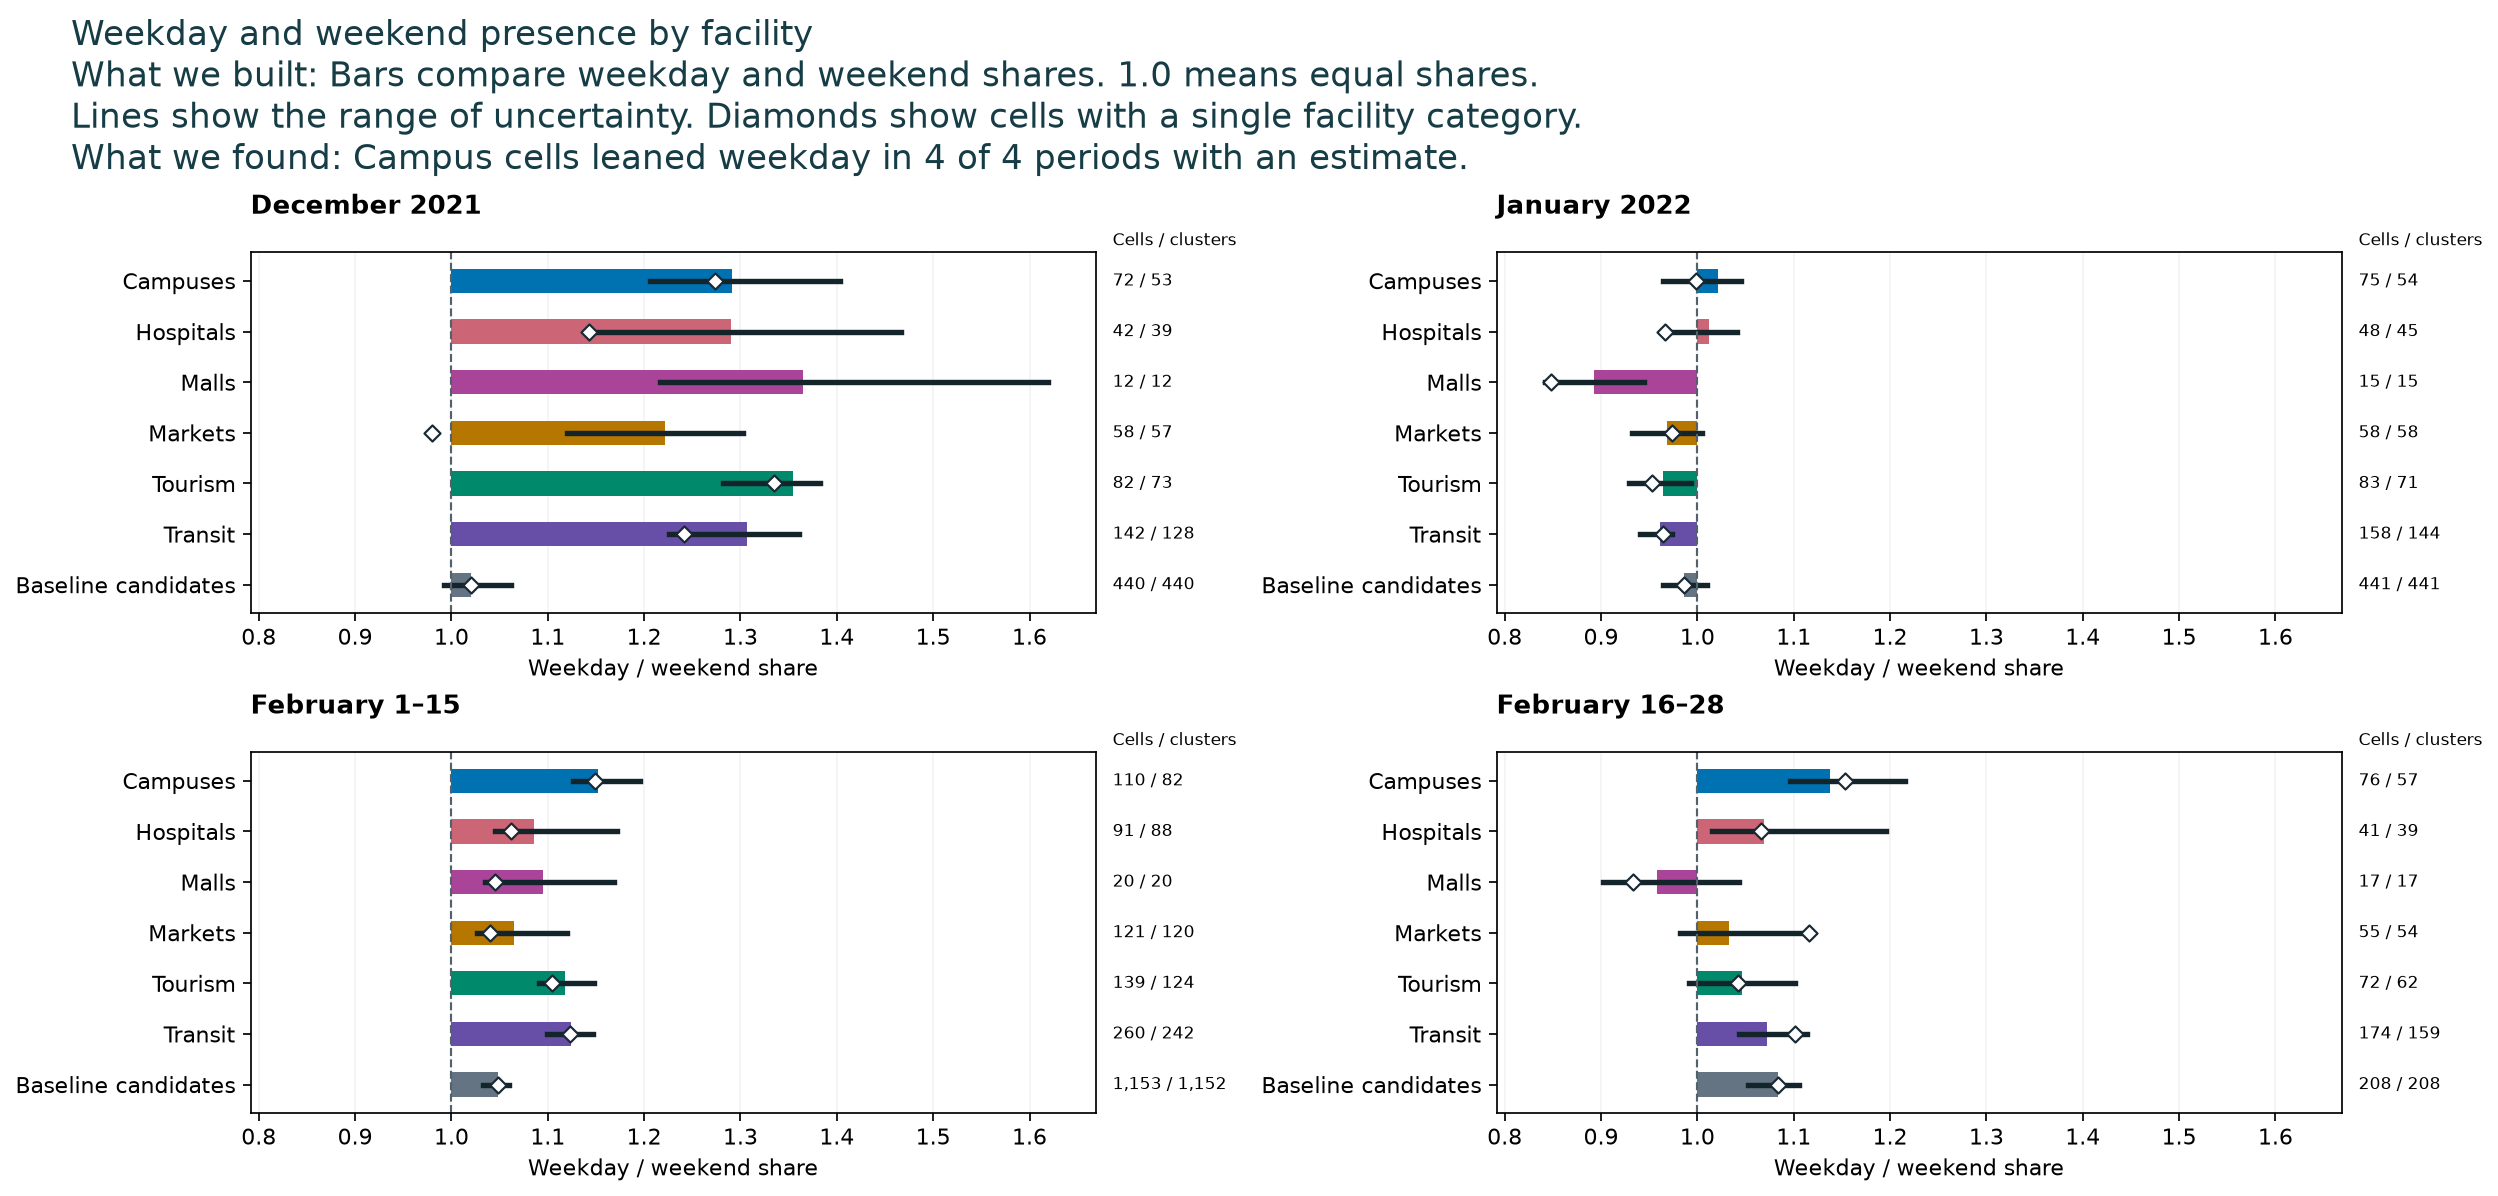

In [4]:
output = Path('weekday_weekend_ratio.png')
rhythm(output)
display(Image(filename=str(output)))